In [15]:
import re
import matplotlib.pyplot as plt
from pyspark import SparkContext, SparkConf
from wordcloud import WordCloud
import os
from math import log

conf = SparkConf().setAppName("Shakespeare_TFIDF_RDD").setMaster("local[*]")
sc = SparkContext(conf=conf)

In [21]:
def clean_and_tokenize(text, STOP_WORDS_EN):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    words = text.split()
    return [w for w in words if w not in STOP_WORDS_EN and len(w) > 2]

def get_doc_id(path):
    return os.path.basename(path)

def calculate_tfidf(word_tf_data, df_map, N):
    word = word_tf_data[0]
    doc_id, tf = word_tf_data[1]
    
    idf = log(N / df_map.get(word, 0)) if df_map.get(word, 0) > 0 else 0
    
    tfidf = tf * idf
    
    return (doc_id, (word, tfidf))

In [18]:
INPUT_FOLDER = "books" 

with open('stop_words_english.txt', 'r') as f:
    STOP_WORDS_EN = set(f.read().splitlines())

whole_files_rdd = sc.wholeTextFiles(INPUT_FOLDER)

tokenized_docs_rdd = whole_files_rdd.map(
    lambda x: (get_doc_id(x[0]), clean_and_tokenize(x[1], STOP_WORDS_EN))
)

tokenized_docs_rdd.cache()

N = tokenized_docs_rdd.count()

In [19]:
tf_rdd = tokenized_docs_rdd.flatMap(lambda doc: [((doc[0], word), 1) for word in doc[1]]) \
                           .reduceByKey(lambda a, b: a + b)

tf_rdd_swapped = tf_rdd.map(lambda x: (x[0][1], (x[0][0], x[1])))

In [20]:
df_rdd = tf_rdd.map(lambda x: (x[0][1], 1)) \
               .reduceByKey(lambda a, b: a + b)

df_map = df_rdd.collectAsMap()

In [22]:
tfidf_rdd = tf_rdd_swapped.map(
    lambda x: calculate_tfidf(x, df_map, N)
)

tfidf_by_doc = tfidf_rdd.groupByKey().mapValues(list)

final_tfidf_results = tfidf_by_doc.collectAsMap()

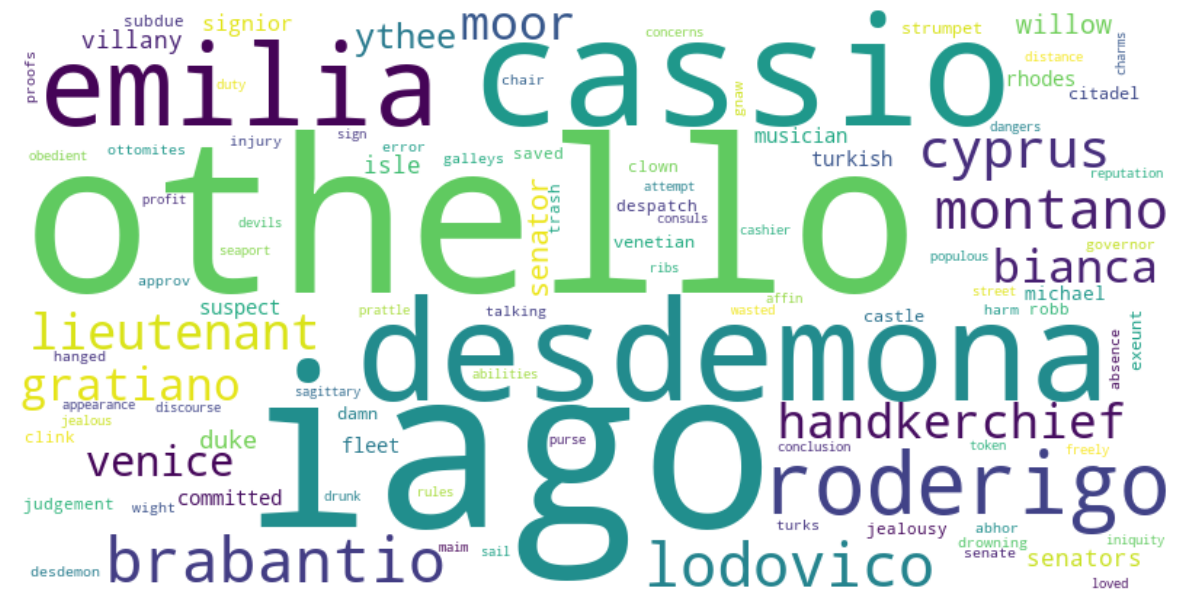

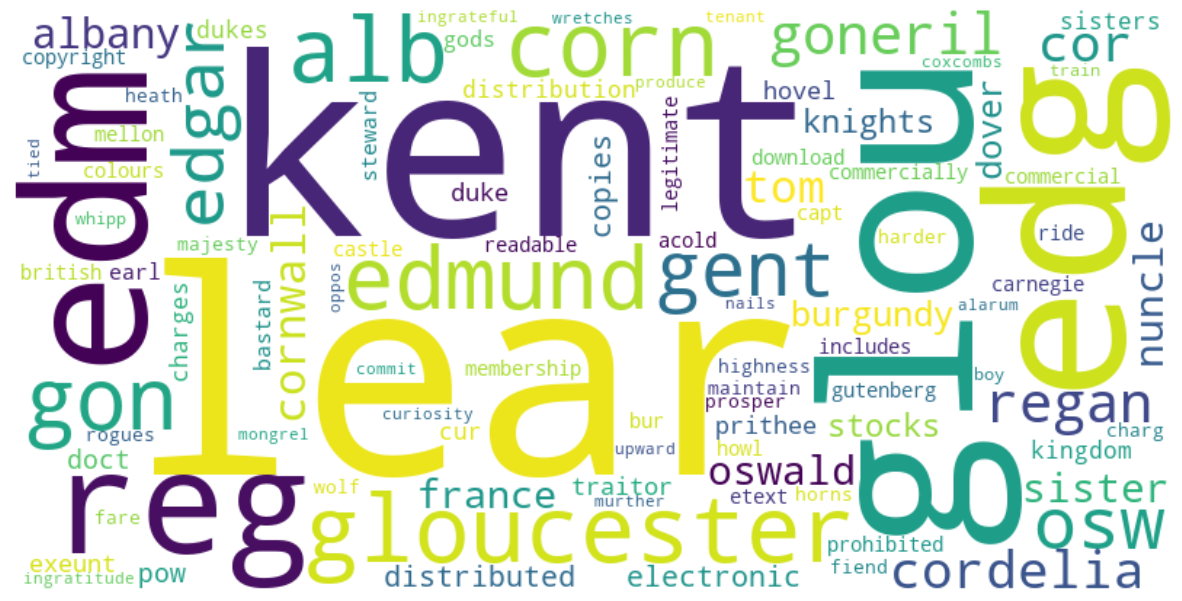

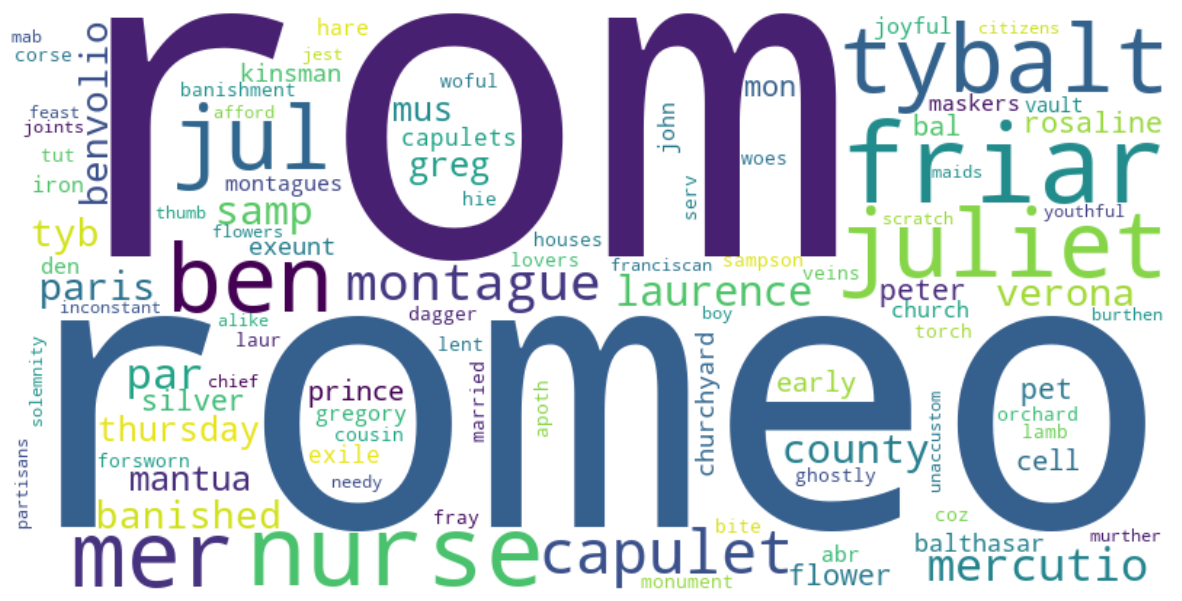

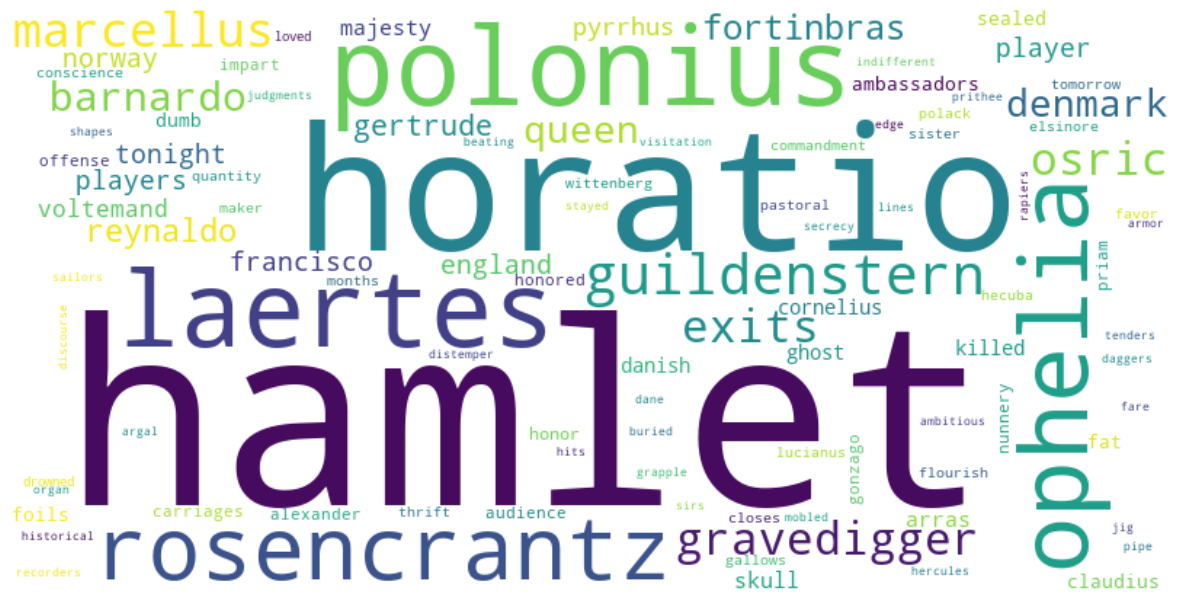

In [24]:
for doc_id, weights_list in final_tfidf_results.items():
    tfidf_weights = dict(weights_list)

    if not tfidf_weights:
        continue

    wordcloud = WordCloud(
        width=800, 
        height=400, 
        background_color='white', 
        max_words=100,
        colormap='viridis'
    )

    wordcloud.generate_from_frequencies(tfidf_weights)

    plt.figure(figsize=(15, 8))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.show()

In [25]:
sc.stop()